# Pulse programs, gradients, phase cycling (beta)

Gradients without a spatial grid, and phase cycles run as pathways. The
pulse programs, the phase-cycle selection and the gradient selection of this
guide are new and in beta: the interface may still change, and the browser
examples are marked the same way.

A pulse program is a sequence written the way it is typed into a spectrometer:
pulses with their phase lists, delays, gradients, an acquisition with its
receiver phases. Spynach does not run the phase cycle. It works out which
coherence transfer pathways the cycle and the gradients let through (with the
[`ctps` module](ctps.ipynb)), propagates one branch of the density matrix per
surviving pathway, and carries a gradient k-vector and a diffusion integral
along each branch. Gradients then never touch the state vector: a branch has
definite coherence orders, so a gradient is the scalar phase `exp(-i k·r)`
whose average over the sample is a sinc envelope, and free diffusion is the
Stejskal–Tanner factor `exp(-D ∫|k|² dt)`, exact for any gradient shape.
That is the point of the module: **gradients without a spatial grid**, no
voxels, no Nyquist condition on the gradient strength, a crusher of a thousand
cycles across the sample at the cost of nothing, where a grid would need two
voxels per cycle. A read gradient during acquisition makes every pathway echo
at its own time.
The explicit cycle can still be run from the same program, as the reference;
there the gradients live on a lattice of Fourier modes along the gradient
axis, again without a grid.
Nothing here has a Spinach counterpart; it assumes the
[pulse sequences](pulse-sequences.ipynb) guide. The companion notebook is
[`notebooks/pulse-programs.ipynb`](pulse-programs.ipynb) ([interactive figures on nbviewer](https://nbviewer.org/github/ajerschow/spynach/blob/main/docs/notebooks/pulse-programs.ipynb)).

Every Python block is executed by `tests/docs/`, in order and in one
namespace. The DQF-COSY, the stimulated-echo phase cycles, the gradient-selected COSY,
the pathway echoes, the PGSE and the 23Na triple-quantum filter below also run in the browser playground
([`try.html#ex-dqf-cosy`](https://ajerschow.github.io/spynach/try.html#ex-dqf-cosy),
[`#ex-phase-cycle`](https://ajerschow.github.io/spynach/try.html#ex-phase-cycle),
[`#ex-gcosy`](https://ajerschow.github.io/spynach/try.html#ex-gcosy),
[`#ex-pathway-echoes`](https://ajerschow.github.io/spynach/try.html#ex-pathway-echoes),
[`#ex-pgse`](https://ajerschow.github.io/spynach/try.html#ex-pgse),
[`#ex-na23-tqf-cycle`](https://ajerschow.github.io/spynach/try.html#ex-na23-tqf-cycle),
[`#ex-na23-tqf-gradients`](https://ajerschow.github.io/spynach/try.html#ex-na23-tqf-gradients)), with
the gradients, delays and the cycle mode in a form.

*Generated from [`docs/pulse-programs.md`](../pulse-programs.md) by `docs/build_notebooks.py`; edit the Markdown guide, not this notebook.*

Run the cells in order: later cells use names defined by earlier ones. The saved outputs come from running the notebook top to bottom; plotting cells need Plotly (`pip install -e ".[docs]"`).

## Contents

1. [Blocks and conventions](#Blocks-and-conventions)
2. [A phase cycle run as pathways: DQF-COSY](#A-phase-cycle-run-as-pathways:-DQF-COSY)
3. [Phase cycles: nested lists, cogwheels, block phases](#Phase-cycles:-nested-lists,-cogwheels,-block-phases)
4. [Gradient selection without a grid](#Gradient-selection-without-a-grid)
5. [Reading pathways out with a gradient](#Reading-pathways-out-with-a-gradient)
6. [Diffusion weighting](#Diffusion-weighting)
7. [The explicit cycle on the Fourier-mode lattice](#The-explicit-cycle-on-the-Fourier-mode-lattice)
8. [A triple-quantum filter for 23Na](#A-triple-quantum-filter-for-23Na)
9. [The pathways in ctps](#The-pathways-in-ctps)
10. [What is checked, and the limits](#What-is-checked,-and-the-limits)

## Blocks and conventions

A `Program` is a list of blocks from `spynach.program`: `Pulse(spins, angle,
phase=[...])` (an isotope, a list of isotopes pulsed together, or 0-based spin
numbers; the flip angle in radians; the phase list in degrees, lists shorter
than the cycle repeating cyclically, or `("cog", nu)` for a cogwheel winding
number with `Program(cycle_length=N)`), `Delay(t, generator="full" |
"relaxation", orders={...})` (free evolution under `L` or under relaxation and
kinetics only; `orders` restricts the coherence orders of the period as a
filter would), `Gradient(duration, z=..., x=..., y=...)` in T/m with its real
duration, `Evolve(dt, n)` for an indirect dimension, `Refocus(dt)` for the
second half of a refocused one (column `k` of the stack evolves `k` more steps,
so `τ/2 – 180° – τ/2` is incremented as one dimension; a second `Evolve`
would evolve every column by every second-half length, an n × n grid), `Homospoil()`, `Block([...], phase=[...])` to
add a phase list to every pulse inside, and one final `Acquire(spins, dt,
npoints, receiver=[...], coil=None, gradient=None)`. Phases follow the
conventions of `ctps` and the CCCP papers: a pulse of phase `φ` is
`cos φ Lx + sin φ Ly`, which multiplies a transfer `p → p'` of the pulsed
isotope by `exp(-i Δp φ)`, and the receiver phase multiplies the signal by
`exp(-i φ_rec)`. Coherence orders are in the textbook convention: the detected
coherence has order `-1`, a 90° pulse on `Lz` makes `±1`, a double-quantum
filter passes `±2`. Spinach labels the basis the other way round: its `L+` coil
state picks the `+1` component and its signal is the complex conjugate of the
textbook one, so the `+1` that `spynach.cosy` keeps in `t1` with `coherence` is
the `-1` of a program, and `Delay(orders=...)` takes the program's sign. The
initial state is `Lz` of the detected isotope and the coil `L+`, as in the
ported sequences, unless `rho0=` and `coil=` say otherwise.

A program is a pulse sequence in Spynach's sense, so the contexts run it
directly. COSY as a program, next to the port (the zero-length delay with
`orders` is the `coherence` filter of `cosy`, applied before the second pulse,
in the program's sign):

In [1]:
import numpy as np

import spynach
from spynach.program import Acquire, Delay, Evolve, Gradient, Homospoil, Program, Pulse, Sample

spin_system = spynach.create(
    {"isotopes": ["1H"] * 3, "magnet": 16.1},
    {"zeeman": {"scalar": [3.70, 3.92, 4.50]}, "coupling": {"scalar": [[0, 10, 4], [0, 0, 12], [0, 0, 0]]}},
)
spin_system = spynach.basis(spin_system, {"formalism": "sphten-liouv", "approximation": "none"})
pars = {
    "angle": np.pi / 2,
    "offset": 2800.0,
    "sweep": 700.0,
    "npoints": [64, 64],
    "zerofill": [256, 256],
    "spins": ["1H"],
    "axis_units": "ppm",
}
dt = 1 / pars["sweep"]
cosy = Program(
    [
        Pulse("1H", np.pi / 2),
        Evolve(dt, 64),
        Delay(0.0, orders={"1H": [-1]}),
        Pulse("1H", np.pi / 2),
        Acquire("1H", dt, 64),
    ]
)
fid = spynach.liquid(spin_system, cosy, pars, "nmr")
print(fid.shape, np.allclose(fid, spynach.liquid(spin_system, spynach.cosy, pars, "nmr")))

(64, 64) True


## A phase cycle run as pathways: DQF-COSY

A double-quantum-filtered COSY with the usual four-step cycle on the first two
pulses and the receiver. `select` returns the pathways that pass the cycle,
per isotope and period, with their complex weights, k-vectors, envelopes and
echo times; `run` (or the context) propagates one branch per pathway and the
explicit cycle is `program.explicit()`:

In [2]:
import time

four = [0, 90, 180, 270]
dqf_cosy = Program(
    [
        Pulse("1H", np.pi / 2, phase=four),
        Evolve(dt, 64),
        Pulse("1H", np.pi / 2, phase=four),
        Delay(3e-6),
        Pulse("1H", np.pi / 2),
        Acquire("1H", dt, 64, receiver=[0, 180, 0, 180]),
    ]
)
selection = dqf_cosy.select(spin_system)
print(selection)
t0 = time.perf_counter()
fid_dqf = spynach.liquid(spin_system, dqf_cosy, pars, "nmr")
t1 = time.perf_counter()
fid_explicit = spynach.liquid(spin_system, dqf_cosy.explicit(), pars, "nmr")
t2 = time.perf_counter()
print(f"pathways {t1 - t0:.2f} s, explicit {dqf_cosy.steps(spin_system)}-step cycle {t2 - t1:.2f} s")
print(
    "largest difference relative to the largest point:",
    np.abs(fid_dqf - fid_explicit).max() / np.abs(fid_explicit).max(),
)

Selection: 14 pathways pass the phase cycle, 14 kept
  1H 0,-3,-2,-1: |pc| 1, phase 0°, |k0| 0 rad/m, envelope 1, echo at 0 ms
  1H 0,-3,+2,-1: |pc| 1, phase 0°, |k0| 0 rad/m, envelope 1, echo at 0 ms
  1H 0,-2,-2,-1: |pc| 1, phase 0°, |k0| 0 rad/m, envelope 1, echo at 0 ms
  1H 0,-2,+2,-1: |pc| 1, phase 0°, |k0| 0 rad/m, envelope 1, echo at 0 ms
  1H 0,-1,-2,-1: |pc| 1, phase 0°, |k0| 0 rad/m, envelope 1, echo at 0 ms
  1H 0,-1,+2,-1: |pc| 1, phase 0°, |k0| 0 rad/m, envelope 1, echo at 0 ms
  1H 0,0,-2,-1: |pc| 1, phase 0°, |k0| 0 rad/m, envelope 1, echo at 0 ms
  1H 0,0,+2,-1: |pc| 1, phase 0°, |k0| 0 rad/m, envelope 1, echo at 0 ms
  1H 0,+1,-2,-1: |pc| 1, phase 0°, |k0| 0 rad/m, envelope 1, echo at 0 ms
  1H 0,+1,+2,-1: |pc| 1, phase 0°, |k0| 0 rad/m, envelope 1, echo at 0 ms
  1H 0,+2,-2,-1: |pc| 1, phase 0°, |k0| 0 rad/m, envelope 1, echo at 0 ms
  1H 0,+2,+2,-1: |pc| 1, phase 0°, |k0| 0 rad/m, envelope 1, echo at 0 ms
  1H 0,+3,-2,-1: |pc| 1, phase 0°, |k0| 0 rad/m, envelope 1, 

The cycle passes every pathway with `Δp ≡ ±2 (mod 4)` at the second pulse,
which for three spins means `p = ±2` in the short delay (the listed pathways
through `p = 0, ±2, ±3` in `t1` are enumerated but carry no amplitude: a 90°
pulse on `Lz` makes single-quantum coherence only, and the runner drops empty
branches). The two results agree to rounding, and the pathway run costs one
pass instead of four. The spectrum, with the antiphase cross peaks and the
absence of the singlet-like diagonal of COSY:

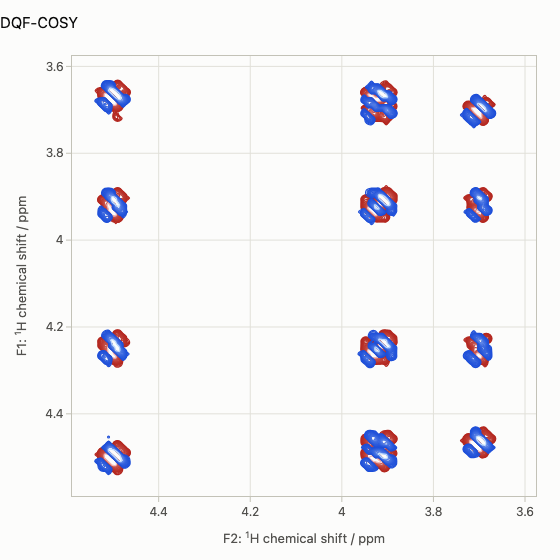

In [3]:
from spynach.plotting import plot_2d

spectrum_dqf = np.fft.fftshift(np.fft.fft2(spynach.apodisation(fid_dqf, [("sqcos",), ("sqcos",)]), pars["zerofill"]))
plot_2d(
    spin_system, spectrum_dqf.real, pars, max_points=128, ncont=20, delta=(0.1, 0.5, 0.1, 0.5), k=2, title="DQF-COSY"
)

## Phase cycles: nested lists, cogwheels, block phases

Phase lists are written per pulse and repeat cyclically, so a nested cycle is
a short list on one pulse and a longer one on another; a cogwheel cycle is
`("cog", nu)` per pulse with `cycle_length=N`; and a `Block` adds one phase list
to every pulse inside it. A stimulated echo on the three-spin system selects
the pathway `0, +1, 0, -1`: the first pulse cycled in four steps (`Δp = +1`),
the third in four steps nested outside it (`Δp = -1`), the receiver following
both, 16 steps in all. `ctps.find_cycle` finds the shortest cogwheel that
selects the same pathway, and the program takes its winding numbers directly;
the three runs (nested, cogwheel, and the nested cycle explicitly) agree:

In [4]:
from ctps import find_cycle

tau, tau_m = 2e-3, 20e-3
m = np.arange(16)
nested = Program(
    [
        Pulse("1H", np.pi / 2, phase=four),
        Delay(tau),
        Pulse("1H", np.pi / 2),
        Delay(tau_m),
        Pulse("1H", np.pi / 2, phase=list(90 * (m // 4))),
        Acquire("1H", dt, 64, receiver=list((-90 * (m % 4) + 90 * (m // 4)) % 360)),
    ]
)
print(nested.select(spin_system))
sequence, _ = nested.to_ctps(spin_system)
solution = find_cycle(sequence, [(0, 1, 0, -1)]).best
print("shortest cogwheel:", solution.cog_string())
cog = Program(
    [
        Pulse("1H", np.pi / 2, phase=("cog", solution.nu[0])),
        Delay(tau),
        Pulse("1H", np.pi / 2, phase=("cog", solution.nu[1])),
        Delay(tau_m),
        Pulse("1H", np.pi / 2, phase=("cog", solution.nu[2])),
        Acquire("1H", dt, 64, receiver=("cog", solution.nu_rec)),
    ],
    cycle_length=solution.N,
)
print(cog.select(spin_system))
fids = {
    "nested": spynach.liquid(spin_system, nested, pars, "nmr"),
    "cogwheel": spynach.liquid(spin_system, cog, pars, "nmr"),
    "explicit nested": spynach.liquid(spin_system, nested.explicit(), pars, "nmr"),
}
for name, value in fids.items():
    print(f"{name}: largest difference from the nested pathway run {np.abs(value - fids['nested']).max():.1e}")

Selection: 2 pathways pass the phase cycle, 2 kept
  1H 0,-3,0,-1: |pc| 1, phase 0°, |k0| 0 rad/m, envelope 1, echo at 0 ms
  1H 0,+1,0,-1: |pc| 1, phase 0°, |k0| 0 rad/m, envelope 1, echo at 0 ms
shortest cogwheel: COG20(0,1,6;7)
Selection: 1 pathways pass the phase cycle, 1 kept
  1H 0,+1,0,-1: |pc| 1, phase 0°, |k0| 0 rad/m, envelope 1, echo at 0 ms
nested: largest difference from the nested pathway run 0.0e+00
cogwheel: largest difference from the nested pathway run 0.0e+00
explicit nested: largest difference from the nested pathway run 3.4e-15


The DQF-COSY above cycles its first two pulses with the same list, which is
block cycling: written with `Block`, the selection and the FID are the same.

In [5]:
from spynach.program import Block

dqf_block = Program(
    [
        Block([Pulse("1H", np.pi / 2), Evolve(dt, 64), Pulse("1H", np.pi / 2)], phase=four),
        Delay(3e-6),
        Pulse("1H", np.pi / 2),
        Acquire("1H", dt, 64, receiver=[0, 180, 0, 180]),
    ]
)
print(
    len(dqf_block.select(spin_system)) == len(selection),
    np.allclose(spynach.liquid(spin_system, dqf_block, pars, "nmr"), fid_dqf),
)

True True


## Gradient selection without a grid

Spinach's `gcosy` selects the P- or N-type COSY with a gradient pair around
the mixing pulse, integrated over the sample by an auxiliary-matrix
exponential (`grad_sandw`). Here the pair is two `Gradient` blocks and the
selection falls out of the k-vectors: a pathway is kept when its envelope
over the acquisition window exceeds `crush_tol`, and every pathway's weight,
envelope and `|k₀|` at the start of acquisition are in the selection. Opposite
gradients keep the `0, -1, -1` pathway (P-type, anti-echo); equal ones would
keep `0, +1, -1` (N-type, echo):

In [6]:
ms = 1e-3
sample = Sample(z_max=5 * ms, x_max=2.5 * ms)  # a 10 mm long, 5 mm wide cylinder
gcosy = Program(
    [
        Pulse("1H", np.pi / 2),
        Evolve(dt, 64),
        Gradient(1 * ms, z=0.5),
        Pulse("1H", np.pi / 2),
        Gradient(1 * ms, z=-0.5),
        Acquire("1H", dt, 64),
    ],
    sample=sample,
)
print(gcosy.select(spin_system))
fid_p = spynach.liquid(spin_system, gcosy, pars, "nmr")
filtered = Program(
    [
        Pulse("1H", np.pi / 2),
        Evolve(dt, 64),
        Delay(1 * ms, orders={"1H": [-1]}),
        Pulse("1H", np.pi / 2),
        Delay(1 * ms),
        Acquire("1H", dt, 64),
    ]
)
fid_f = spynach.liquid(spin_system, filtered, pars, "nmr")
print("gradient-selected against filtered:", np.abs(fid_p - fid_f).max() / np.abs(fid_f).max())

Selection: 7 pathways pass the phase cycle, 1 kept
  1H 0,-1,-1: |pc| 1, phase 0°, |k0| 0 rad/m, envelope 1, echo at 0 ms
  1H 0,-2,-1: |pc| 1, phase 0°, |k0| 1.34e+05 rad/m, envelope 0.000518 (crushed)
  1H 0,0,-1: |pc| 1, phase 0°, |k0| 1.34e+05 rad/m, envelope 0.000518 (crushed)
  1H 0,-3,-1: |pc| 1, phase 0°, |k0| 2.68e+05 rad/m, envelope 0.000486 (crushed)
  1H 0,+1,-1: |pc| 1, phase 0°, |k0| 2.68e+05 rad/m, envelope 0.000486 (crushed)
  1H 0,+2,-1: |pc| 1, phase 0°, |k0| 4.01e+05 rad/m, envelope 0.000435 (crushed)
  1H 0,+3,-1: |pc| 1, phase 0°, |k0| 5.35e+05 rad/m, envelope 0.000369 (crushed)
gradient-selected against filtered: 0.0


The crushed pathways would contribute their sinc residual, about `1/(k z_max)`
of the echo; with 0.5 T/m for 1 ms that is below `crush_tol` and they are not
propagated at all, so the gradient-selected FID equals the filtered one with
the same delays. The gradient costs nothing: no spatial grid, no Nyquist
condition on a voxel size (a grid would need two voxels per cycle of the
helix, here over a thousand cycles across the sample).

## Reading pathways out with a gradient

With a read gradient during acquisition every pathway's `k(t)` moves linearly,
and a pathway refocuses when it crosses zero: the pathways arrive as separate
echoes. Three 90° pulses with gradients of area 1 and 2 (in units of `G δ`)
between them, then a read gradient of the same strength and opposite sign:
the pathway `0, p1, p2, -1` has `k₀ = γ G δ (p1 + 2 p2)`, the read gradient
moves it at `-γ G δ` per `δ`, and it echoes at `t = -(p1 + 2 p2) δ`.
`output="pathways"` returns the FID of every propagated pathway:

In [7]:
from spynach.plotting import plot_time_series

delta, G = 1 * ms, 0.05
readout = Program(
    [
        Pulse("1H", np.pi / 2),
        Gradient(delta, z=G),
        Pulse("1H", np.pi / 2),
        Gradient(2 * delta, z=G),
        Pulse("1H", np.pi / 2),
        Acquire("1H", 10e-6, 800, gradient=Gradient(0, z=-G)),
    ],
    sample=sample,
    crush_tol=0.05,
)
read_selection = readout.select(spin_system)
paths = spynach.liquid(spin_system, lambda ss, p, H, R, K: readout.run(ss, H, R, K, output="pathways"), pars, "nmr")
for i in range(len(paths.index)):
    echo = paths.echo_time[i]
    print(f"{paths.pathway(i)}: echo at {echo * 1e3:.0f} ms, largest |FID| {np.abs(paths.fids[i]).max():.3f}")

1H 0,-1,-3,-1: echo at 7 ms, largest |FID| 0.000
1H 0,-1,-2,-1: echo at 5 ms, largest |FID| 0.002
1H 0,-1,-1,-1: echo at 3 ms, largest |FID| 0.397
1H 0,-1,0,-1: echo at 1 ms, largest |FID| 1.069
1H 0,0,-1,-1: echo at 2 ms, largest |FID| 0.000
1H 0,+1,-3,-1: echo at 5 ms, largest |FID| 0.000
1H 0,+1,-2,-1: echo at 3 ms, largest |FID| 0.001
1H 0,+1,-1,-1: echo at 1 ms, largest |FID| 0.529


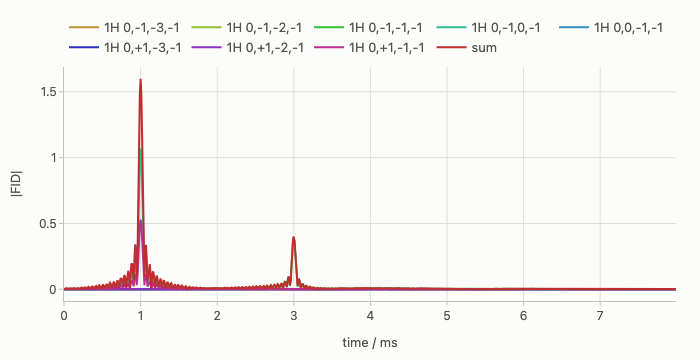

In [8]:
t_axis = np.arange(800) * 10e-6 * 1e3
plot_time_series(
    t_axis,
    [np.abs(paths.fids[i]) for i in range(len(paths.index))] + [np.abs(paths.sum())],
    names=[paths.pathway(i) for i in range(len(paths.index))] + ["sum"],
    xlabel="time / ms",
    ylabel="|FID|",
)

Each echo is the sinc envelope of the sample, `2π / (γ G z_max)` wide;
pathways with the same `k₀` overlap, as they would in the spectrometer, and
the pathways that never refocus in the window (`p1 + 2 p2 ≥ 0`) are dropped by
`crush_tol` before they are propagated (the default of `1e-3` would keep their
sinc residuals). The summed FID is what a detector would record.

## Diffusion weighting

The diffusion integral `b = ∫|k(t)|² dt` is accumulated along each branch with
the exact ramp integral over every rectangular gradient, so a pulsed-gradient
spin echo reproduces the Stejskal–Tanner attenuation
`exp(-D γ² G² δ² (Δ - δ/3))` including the finite-width term, with no
narrow-gradient approximation:

In [9]:
water = spynach.basis(
    spynach.create({"isotopes": ["1H"], "magnet": 14.1}, {"zeeman": {"scalar": [4.7]}}),
    {"formalism": "sphten-liouv", "approximation": "none"},
)
pars_water = {"spins": ["1H"], "offset": 4.7 * 42.577478 * 14.1}
D, delta, big_delta = 2.3e-9, 2 * ms, 50 * ms
gamma = water.gammas[0]


def pgse(G, diffusion):
    return Program(
        [
            Pulse("1H", np.pi / 2),
            Gradient(delta, z=G),
            Delay(big_delta - delta),
            Pulse("1H", np.pi),
            Gradient(delta, z=G),
            Acquire("1H", 1e-3, 4),
        ],
        diffusion=diffusion,
    )


for G in (0.05, 0.1, 0.2, 0.4):
    signal = spynach.liquid(water, pgse(G, D), pars_water, "nmr")[0]
    reference = spynach.liquid(water, pgse(G, 0.0), pars_water, "nmr")[0]
    b = gamma**2 * G**2 * delta**2 * (big_delta - delta / 3)
    print(
        f"G = {G:.2f} T/m: b = {b * 1e-6:7.3f} s/mm², attenuation {abs(signal / reference):.4f}, Stejskal-Tanner {np.exp(-D * b):.4f}"
    )

G = 0.05 T/m: b =  35.307 s/mm², attenuation 0.9220, Stejskal-Tanner 0.9220
G = 0.10 T/m: b = 141.228 s/mm², attenuation 0.7227, Stejskal-Tanner 0.7227
G = 0.20 T/m: b = 564.911 s/mm², attenuation 0.2727, Stejskal-Tanner 0.2727
G = 0.40 T/m: b = 2259.644 s/mm², attenuation 0.0055, Stejskal-Tanner 0.0055


## The explicit cycle on the Fourier-mode lattice

`program.explicit()` runs the phase cycle step by step with the whole density
matrix, and it takes the same gradients. It cannot carry a k-vector per
pathway, since it does not know the pathways; instead the state is expanded in
Fourier modes along the gradient axis, `ρ(s) = Σₙ ρₙ exp(i n k₀ s)`, one state
vector per integer `n`. The base wavevector is `k₀ = γ A₀` for the base area
`A₀` of which every gradient area in the program (the read gradient per
dwell included) is an integer multiple: `Program(gradient_unit=A₀)` sets it,
and by default it is the smallest area present. A pulse and a delay act on
every mode alike, so the modes are just more columns of the state; a gradient
of `m` units moves the coherence-order-`p` block of mode `n` to mode
`n + m p`, which is a relabelling, not a propagation; detection weights mode
`n` with the sample envelope at `n k₀` and sums. All gradients must be
collinear (in any direction), and a second isotope may not carry coherence
during a gradient unless the gyromagnetic ratios are commensurate. Pathway
by pathway or mode by mode, the two runs are the same sum:

In [10]:
from dataclasses import replace

all_paths = spynach.liquid(
    spin_system, lambda ss, p, H, R, K: replace(readout, crush_tol=0.0).run(ss, H, R, K), pars, "nmr"
)
modes = spynach.liquid(
    spin_system, lambda ss, p, H, R, K: readout.explicit().run(ss, H, R, K, output="modes"), pars, "nmr"
)
print("explicit lattice against every pathway:", np.abs(modes.sum() - all_paths).max() / np.abs(all_paths).max())
print(f"{modes.modes.size} modes, k0 = {modes.k0:.1f} rad/m (the read gradient per dwell)")
strong = np.flatnonzero(np.abs(modes.fids).max(axis=1) > 0.05 * np.abs(modes.fids).max())
for i in strong:
    print(f"mode {modes.modes[i]:+d}: echo at {np.argmax(np.abs(modes.fids[i])) * 10e-6 * 1e3:.0f} ms")

explicit lattice against every pathway: 4.0668884236277426e-14
6595 modes, k0 = 133.8 rad/m (the read gradient per dwell)
mode -26: echo at 1 ms
mode -22: echo at 1 ms
mode -21: echo at 1 ms
mode -20: echo at 1 ms
mode -17: echo at 1 ms
mode -16: echo at 1 ms
mode -15: echo at 1 ms
mode -13: echo at 1 ms
mode -12: echo at 1 ms
mode -11: echo at 1 ms
mode -10: echo at 1 ms
mode -8: echo at 1 ms
mode -7: echo at 1 ms
mode -6: echo at 1 ms
mode -5: echo at 1 ms
mode -4: echo at 1 ms
mode -3: echo at 1 ms
mode -2: echo at 1 ms
mode -1: echo at 1 ms
mode +0: echo at 1 ms
mode +1: echo at 1 ms
mode +2: echo at 1 ms
mode +3: echo at 1 ms
mode +4: echo at 1 ms
mode +5: echo at 1 ms
mode +6: echo at 1 ms
mode +7: echo at 1 ms
mode +8: echo at 1 ms
mode +10: echo at 1 ms
mode +11: echo at 1 ms
mode +12: echo at 1 ms
mode +13: echo at 1 ms
mode +15: echo at 1 ms
mode +16: echo at 1 ms
mode +17: echo at 1 ms
mode +20: echo at 1 ms
mode +21: echo at 1 ms
mode +22: echo at 1 ms
mode +26: echo at 1 m

The echoes of the previous section appear at the modes the read gradient
carries through zero, one dwell at a time. Every pathway is there, including
the ones `crush_tol` dropped from the pathway run (hence the comparison against
`crush_tol=0`); the price is the cycle run step by step and a state as wide
as the lattice. The lattice holds the whole state at each wavevector, which
is what a mean-field term needs: the
[distant dipolar field](distant-dipolar-field.ipynb) is computed on it.

## A triple-quantum filter for 23Na

A spin-3/2 such as 23Na outside extreme narrowing relaxes biexponentially,
and the quadrupolar relaxation turns the single-quantum `T(1,±1)` into the
rank-3 `T(3,±1)` (the build-up notebook `user_py/na23_tqf_buildup.ipynb`). A
triple-quantum filter detects it: `90°x – τ/2 – 180°y – τ/2 – 90°y – δ – 90°x –
acquire`, the preparation block stepped through six phases 60° apart with the
receiver alternating, which passes `Δp = ±3` over the block. The second
preparation pulse is 90° out of phase with the first on purpose: relaxation
keeps the y type of the magnetisation the first pulse made, and a 90° pulse
along x turns a y-type rank-3 tensor into even orders only (`T(3,0)`,
`T(3,±2)`), making no triple-quantum coherence at all. With `τ` as an indirect
dimension (`Evolve` for the first half, `Refocus` for the second) one run
returns the whole build-up curve:

In [11]:
from spynach.conventions import eeqq2nqi
from spynach.program import Refocus

nqi = eeqq2nqi(200e3, 0.0, 1.5, [0, 0, 0])
sodium = spynach.create(
    {"isotopes": ["23Na"], "magnet": 14.1},
    {
        "coupling": {"matrix": [[nqi.tolist()]]},
        "relaxation": ["redfield"],
        "rlx_keep": "secular",
        "equilibrium": "dibari",
        "temperature": 298.0,
        "tau_c": [[1e-9]],
    },
)
sodium = spynach.assume(spynach.basis(sodium, {"formalism": "sphten-liouv", "approximation": "none"}), "nmr")
H_na, R_na = spynach.hamiltonian(sodium), spynach.relaxation(sodium)
rho_eq = spynach.equilibrium(sodium)  # the thermalised relaxation needs the unit state
ntau, d_tau, delta = 16, 1.6 * ms, 1 * ms
tau_axis = np.arange(ntau) * d_tau


def preparation():
    return [
        Pulse("23Na", np.pi / 2),
        Evolve(d_tau / 2, ntau, name="tau"),
        Pulse("23Na", np.pi, phase=(90.0,)),
        Refocus(d_tau / 2),
        Pulse("23Na", np.pi / 2, phase=(90.0,)),
    ]


def tqf_cycle(offset):
    return Program(
        [
            Block(preparation(), phase=[offset + 60 * n for n in range(6)]),
            Delay(delta),
            Pulse("23Na", np.pi / 2),
            Acquire("23Na", 50e-6, 200, receiver=[0, 180]),
        ],
        rho0=rho_eq,
    )


def peak(fid):  # the spectrum at the resonance (the FID integral), for every tau
    return np.abs(fid.sum(axis=0))


def routes(fids):  # by the order after the first pulse: ±1 transverse, 0 longitudinal
    orders = fids.selection.orders[fids.index, 0, :]
    return fids.fids[np.abs(orders[:, 1]) == 1].sum(axis=0), fids.fids[orders[:, 1] == 0].sum(axis=0)


tqf = tqf_cycle(30)
tqf_paths = tqf.run(sodium, H_na, R_na, 0 * R_na, output="pathways")
print(len(tqf_paths.selection), "pathways pass the cycle,", len(tqf_paths.index), "carry amplitude")
explicit = tqf.explicit().run(sodium, H_na, R_na, 0 * R_na)
print("against the explicit six-step cycle:", np.abs(tqf_paths.sum() - explicit).max() / np.abs(explicit).max())

98 pathways pass the cycle, 50 carry amplitude
against the explicit six-step cycle: 2.6543795350005735e-13


The cycle passes every `Δp = ±3` over the block, but only two routes carry
amplitude: the transverse one, `0, ±1, ∓1, ±3, -1` through `T(3,±1)`, and the
longitudinal one, `0, 0, 0, ±3, -1` through the `T(3,0)` that builds up as
`Lz` recovers. The first phase of the cycle decides between them: the two
signs of the transverse route add at 30° and cancel at 0°, the longitudinal
route the other way round, which is why the textbook cycle starts at 30°:

In [12]:
one_pulse = Program([Pulse("23Na", np.pi / 2), Acquire("23Na", 50e-6, 200)], rho0=rho_eq)
unit = peak(one_pulse.run(sodium, H_na, R_na, 0 * R_na)).max()
by_offset = {}
for offset in (30, 0):
    transverse, longitudinal = routes(tqf_cycle(offset).run(sodium, H_na, R_na, 0 * R_na, output="pathways"))
    by_offset[offset] = (transverse, longitudinal)
    print(
        f"first phase {offset:2d}°: transverse route {peak(transverse).max() / unit:.4f}, "
        f"longitudinal {peak(longitudinal).max() / unit:.4f} of the single-pulse signal"
    )

first phase 30°: transverse route 0.0160, longitudinal 0.0000 of the single-pulse signal
first phase  0°: transverse route 0.0000, longitudinal 0.0107 of the single-pulse signal


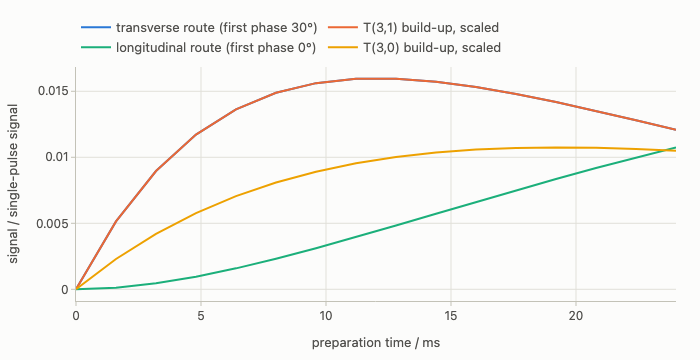

In [13]:
Lx_na = spynach.operator(sodium, "Lx", "23Na")
after_pulse = spynach.step(sodium, Lx_na, rho_eq, np.pi / 2)
traj = spynach.evolution(sodium, H_na + 1j * R_na, after_pulse, d_tau, ntau - 1, "trajectory")
a31 = np.abs(spynach.state(sodium, ["T3,1"], [0], "cheap") @ traj)
a30 = np.abs(spynach.state(sodium, ["T3,0"], [0], "cheap") @ traj)
s_trans = peak(by_offset[30][0]) / unit
s_long = peak(by_offset[0][1]) / unit
plot_time_series(
    tau_axis * 1e3,
    [s_trans, a31 * s_trans.max() / a31.max(), s_long, a30 * s_long.max() / a30.max()],
    names=[
        "transverse route (first phase 30°)",
        "T(3,1) build-up, scaled",
        "longitudinal route (first phase 0°)",
        "T(3,0) build-up, scaled",
    ],
    xlabel="preparation time / ms",
    ylabel="signal / single-pulse signal",
)

The transverse route follows the `T(3,1)` build-up of the tensor projection
to rounding (the conversion to `T(3,±3)`, the delay and the detection add a
constant factor), the longitudinal route the `T(3,0)` build-up, which peaks
later and goes with the longitudinal rates.

Gradients select without the cycle. The wanted pathway has the orders `+1,
-1, +3, -1` between the pulses: a gradient after the first pulse winds its
`+1` up (the 180° flips the order, not the accumulated `k`), one after the
third pulse its `+3`, and one before acquisition unwinds the `-1` that is
detected, so areas `1 : 1 : 4` refocus it alone. The longitudinal route
(`0, 0, +3`) lands at `1k`, the mirror route (`-1, +1, -3`) at `8k`, and the
magnetisation that recovers along `z` during the gradients, order 0 until the
last pulse, at `4k`, which is what the last gradient is for: a pair around the
third pulse alone would pass that recovery at 4% of a single-pulse signal per
millisecond of gradient, ten times the triple-quantum signal (23Na's `T1` is
short). The price is one of the two transverse pathways, a quarter of the
cycle's signal, and the single-quantum pathways refocused at `2k` to `4k`,
which leak through the sinc tails of the uniform sample as `1 / (k z_max)`.
The branch run makes the comparison with the cycle exact: the refocused
pathway of the gradient program is the same pathway of the cycle once each is
stripped of its weight (the y pulses give the uncycled program a phase per
pathway too):

In [14]:
def tqf_gradients(G):
    return Program(
        [
            Pulse("23Na", np.pi / 2),
            Gradient(delta, z=G),
            Evolve(d_tau / 2, ntau, name="tau"),
            Pulse("23Na", np.pi, phase=(90.0,)),
            Refocus(d_tau / 2),
            Delay(delta),  # the two halves of tau stay equal
            Pulse("23Na", np.pi / 2, phase=(90.0,)),
            Gradient(delta, z=G),
            Pulse("23Na", np.pi / 2),
            Gradient(delta, z=4 * G),
            Acquire("23Na", 50e-6, 200),
        ],
        rho0=rho_eq,
    )


grad_paths = tqf_gradients(0.3).run(sodium, H_na, R_na, 0 * R_na, output="pathways")
grad_orders = grad_paths.selection.orders[grad_paths.index, 0, :]
amplitude = np.array([peak(f).max() for f in grad_paths.fids])
refocused = (grad_paths.selection.envelope[grad_paths.index] > 0.999) & (amplitude > 1e-6 * amplitude.max())
longitudinal = (grad_orders[:, 1] == 0) & (np.abs(grad_orders[:, -2]) == 3)
leak = grad_paths.fids[~refocused & ~longitudinal].sum(axis=0)
print(
    "refocused:",
    [grad_paths.selection.pathway(i) for i in grad_paths.index[refocused]],
    f"{peak(grad_paths.fids[refocused].sum(axis=0)).max() / unit:.4f} of the single-pulse signal;",
    f"longitudinal route {peak(grad_paths.fids[longitudinal].sum(axis=0)).max() / unit:.5f}, sinc tails {peak(leak).max() / unit:.4f}",
)
# the cycled reference with delays where the gradient program has its gradients
padded = [
    Pulse("23Na", np.pi / 2),
    Delay(delta),
    Evolve(d_tau / 2, ntau, name="tau"),
    Pulse("23Na", np.pi, phase=(90.0,)),
    Refocus(d_tau / 2),
    Delay(delta),
    Pulse("23Na", np.pi / 2, phase=(90.0,)),
]
reference = Program(
    [
        Block(padded, phase=[30 + 60 * n for n in range(6)]),
        Delay(delta),
        Pulse("23Na", np.pi / 2),
        Delay(delta),
        Acquire("23Na", 50e-6, 200, receiver=[0, 180]),
    ],
    rho0=rho_eq,
)
ref_paths = reference.run(sodium, H_na, R_na, 0 * R_na, output="pathways")
bare = {
    tuple(ref_paths.selection.orders[i, 0, :]): ref_paths.fids[n] / np.conj(ref_paths.selection.pc[i])
    for n, i in enumerate(ref_paths.index)
}
from_cycle = sum(
    bare[tuple(grad_orders[n])] * np.conj(grad_paths.selection.pc[i])
    for n, i in enumerate(grad_paths.index)
    if refocused[n]
)
print(
    "the refocused pathway against the cycle:",
    np.abs(grad_paths.fids[refocused].sum(axis=0) - from_cycle).max() / np.abs(from_cycle).max(),
)

refocused: ['23Na 0,+1,-1,+3,-1'] 0.0045 of the single-pulse signal; longitudinal route 0.00003, sinc tails 0.0013
the refocused pathway against the cycle: 4.022719853201697e-13


Both run in the browser with the coupling, the correlation time, the first
phase and the gradients in a form
([`#ex-na23-tqf-cycle`](https://ajerschow.github.io/spynach/try.html#ex-na23-tqf-cycle),
[`#ex-na23-tqf-gradients`](https://ajerschow.github.io/spynach/try.html#ex-na23-tqf-gradients)).

## The pathways in ctps

`to_ctps` turns a program into a `ctps.Sequence` and `ctps.PhaseCycle` (orders
from the basis, the start from `rho0`, the end from the coil, gradients as
deltas of the same area), which is how `select` gets its weights; the
`ctps.PathwayResult` behind a selection is its `result`, so the pathway
explorer and the cycle search of `ctps` apply to a program as they are:

explicit cycle, 4 steps, base 4 | 3 pulses, 4 periods


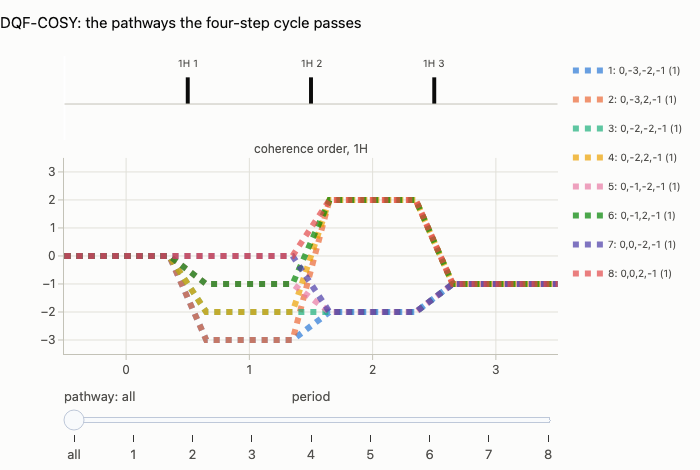

In [15]:
from ctps.plot import plot_pathways

sequence, cycle = dqf_cosy.to_ctps(spin_system)
print(cycle.cog_string(), "|", sequence.n_pulses, "pulses,", sequence.n_periods, "periods")
plot_pathways(selection.result, top=8, title="DQF-COSY: the pathways the four-step cycle passes")

The enumeration grows as the number of allowed orders to the power of the
number of pulses on a nucleus, as in `ctps`; `Delay(orders=...)` restrictions
and `Program(max_order=...)` keep it small for long sequences.

## What is checked, and the limits

The pathway run equals the explicit cycle exactly when free evolution
conserves the coherence order of every isotope: a rotating-frame Hamiltonian
with secular relaxation, the same assumption a phase cycle itself relies on.
`Program(check_leakage=True)` measures it instead of trusting it: for every
order block a branch visits, the fraction of the generator's 1-norm that
leaves the block is recorded in `selection.leakage` after a run (zero here,
and large for a generator with a transverse field or non-secular terms, where
only the explicit cycle is right):

In [16]:
checked = Program(list(dqf_cosy.blocks), check_leakage=True)
checked_selection = checked.select(spin_system)
spynach.liquid(spin_system, lambda ss, p, H, R, K: checked.run(ss, H, R, K, selection=checked_selection), pars, "nmr")
print(checked_selection.leakage)

{'full 1H:-1': 0.0, 'full 1H:+0': 0.0, 'full 1H:+1': 0.0, 'full 1H:-2': 0.0, 'full 1H:+2': 0.0}


The limits of the branch model, by construction: rf during a gradient (slice
selection), B1 inhomogeneity, spatially structured samples and restricted
diffusion are not representable; the sample is a uniform cylinder, diffusion
free. The explicit mode carries the gradients on the Fourier-mode lattice,
so it needs collinear gradients with areas on one integer grid.

`tests/unit/test_program.py` checks, against a hand-written phase cycle loop
over `step` and `evolution`: the DQF-COSY cycle (1-D and 2-D), partial weights
of a three-step list, a four-step cycle on five spins that also passes
`Δp = +3` and `−5`, nested, cogwheel and block cycles, an eight-step
heteronuclear cycle with pulses on both channels, and the explicit mode; every
gradient program of the file in explicit mode against the pathway runner
(the Fourier-mode lattice: an inclined axis, a read gradient, diffusion, an
indirect dimension, a phase cycle, the 23Na filter) and the lattice's errors; the
COSY, NOESY (States) and HSQC (echo/antiecho) programs against the ported
sequences (which pins the sign convention: a program's order is minus
Spinach's, and the receiver acts as `exp(+i φ_rec)` on Spinach's conjugate
signal); the gradients against an explicit average over 2001 sample
positions with the gradient as a field term (a pair, a crusher, a read-gradient
echo), echo/antiecho and three-gradient chains against coherence filters, PGSE
against Stejskal–Tanner and, in the narrow-gradient limit, against the
diffusion factor of `ctps`; the 23Na triple-quantum filter (the six-step cycle
against the explicit one, the first phase selecting the route, and the
gradient program against the cycle's own pathways); the leakage number; and
the `to_ctps` round trip.